### 💡 Confusion Matrix (혼동 행렬)

혼동 행렬이란 분류 모델의 실제 정답과 예측 결과를 비교하여 모델이 어떤 예측을 맞히고 틀렸는지 확인하는 표이다.

예를 들어 스팸메일을 분류하는 모델이 있다고 가정했을 때 아래와 같은 결과가 나왔다고 해보자

- 0: 정상 메일 (Negative)
- 1: 스팸 메일 (Positive)

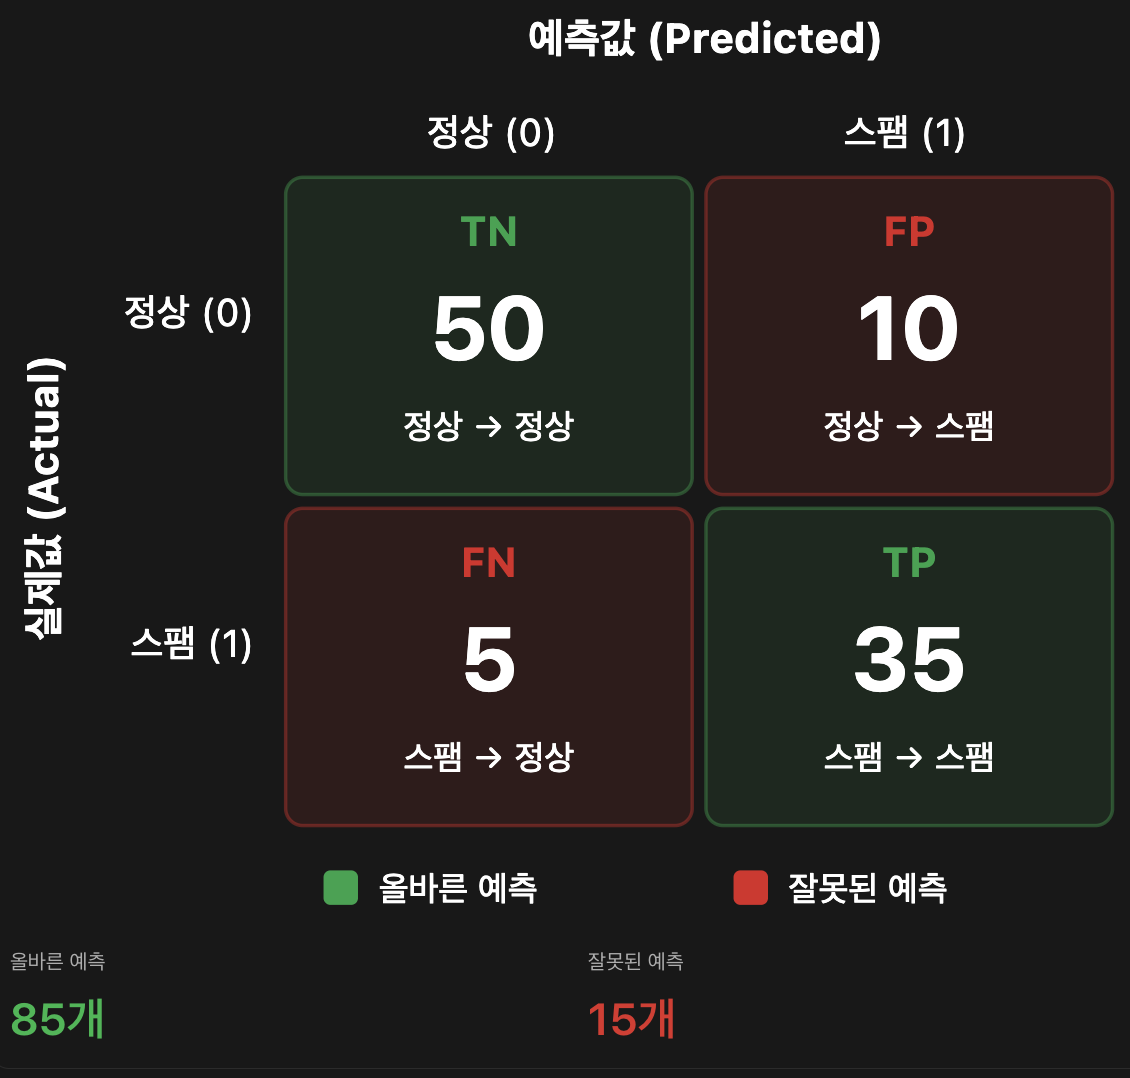

단순히 정확도가 85%라는 사실만 확인하는 것보다 어떤 종류의 예측을 틀렸는지를 확인할 수 있는 것이 혼동 행렬의 장점이다.

### ✅ TP, TN, FP, FN의 이해
- True (T) : 모델의 예측이 맞음
- False (F) : 모델의 예측이 틀림
- Positive (P) : 모델이 양성(1)으로 예측
- Negative (N) : 모델이 음성(0)으로 예측

> 앞글자는 예측의 성공 여부, 뒷글자는 모델이 예측한 클래스

| 구분 | 실제값 | 예측값 | 예측 결과 |
| --- | --- | --- | --- |
| TP | 1 | 1 | 성공 |
| TN | 0 | 0 | 성공 |
| FP | 0 | 1 | 실패 |
| FN | 1 | 0 | 실패 |

In [4]:
# confusion Matrix 계산하기
import numpy as np
from sklearn.metrics import confusion_matrix

# 실제 정답
y_true = np.array([0, 0, 0, 0, 0, 1, 1, 1, 1, 1])

# 모델 예측값
y_pred = np.array([0, 0, 0, 0, 1, 0, 1, 1, 1, 1])

cm = confusion_matrix(y_true, y_pred)
print(cm)

[[4 1]
 [1 4]]


scikit-learn에서 클래스 순서가 [0, 1]인 경우 혼동 행렬의 구조는 아래와 같다.

$\begin{bmatrix} TN & FP\\FN & TP\end{bmatrix}$

- 행(Row): 실제값
- 열(Column): 예측값

In [ ]:
# TP, NP, FP, FN 각각 추출해보기
# ravel() : 다차원 배열을 1차원 배열로 펼치는 함수
tn, fp, fn, tp = cm.ravel()

print("TN:", tn)
print("FP:", fp)
print("FN:", fn)
print("TP:", tp)

TN: 4
FP: 1
FN: 1
TP: 4


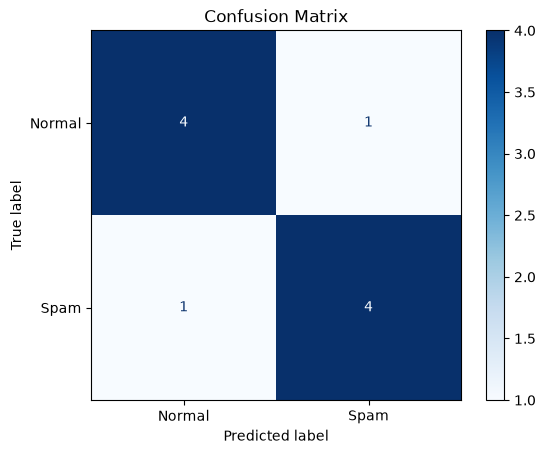

In [ ]:
# confusion matrix 시각화
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Normal", "Spam"]
)

display.plot(cmap="Blues")

plt.title("Confusion Matrix")
plt.show()

In [13]:
# Decision Tree에 혼동 행렬 적용해보기
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import confusion_matrix

data = load_breast_cancer()

X = data.data
y = data.target

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

model = DecisionTreeClassifier(
    random_state=42
)

model.fit(X, y)

y_pred = model.predict(X_test)

cm = confusion_matrix(y_test, y_pred)
cm

array([[43,  0],
       [ 0, 71]])

---
#### 실습문제

In [ ]:
import numpy as np
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

y_true = np.array([
    0, 0, 0, 0, 0,
    0, 0, 0, 0, 0,
    1, 1, 1, 1, 1,
    1, 1, 1, 1, 1
])

y_pred = np.array([
    0, 0, 1, 0, 0,
    0, 1, 0, 0, 0,
    1, 1, 0, 1, 1,
    0, 1, 1, 0, 1
])

# 1. confusion_matrix()를 이용해 혼동 행렬 생성
cm = confusion_matrix(y_true, y_pred)

# 2. 혼동 행렬 출력
print(cm)

# 3. NumPy 인덱싱으로 TN, FP, FN, TP 추출
TN = cm[0, 0]
FP = cm[0, 1]
FN = cm[1, 0]
TP = cm[1, 1]

# 4. ravel()을 이용해 TN, FP, FN, TP 추출
TN, FP, FN, TP = cm.ravel()

# 5. 올바르게 예측한 데이터 개수 출력
print(TP + TN)

# 6. 잘못 예측한 데이터 개수 출력
print(FP + FN)

# 7. 전체 데이터 개수 출력
print(TP + TN + FP + FN)

[[8 2]
 [3 7]]
15
5
20
